# 01 · The data: 64 winters of daily rainfall over Cumbria

**Source:** HadUK-Grid v1.3.2.ceda, daily rainfall on a 5 km grid (Met Office, via CEDA; Open
Government Licence v3.0). The pilot uses an 80 km × 80 km box (16 × 16 cells) over the Lake
District, October–March only, for the winters of 1961/62 to 2024/25.

**Why Cumbria:** it contains the wettest terrain in England, and on 5 December 2015 Storm Desmond
brought the largest daily rainfall in this record. That day is **held out** and used as a stress
test in notebook 03.

This notebook only *describes* the data. The split and the 95% threshold of the EVT margins were
fixed before any model was fitted. Choices made later, after looking at results, are listed in the
README under "Choices made after seeing results".

In [1]:
# Setup: works locally (from the repository root or notebooks/) and on Google Colab
import sys, os
from pathlib import Path
if "google.colab" in sys.modules and not Path("rainfall-extremes-pilot").exists():
    !git clone -q https://github.com/RidhimaGupta4/rainfall-extremes-pilot.git
    os.chdir("rainfall-extremes-pilot")
    !pip install -q -r requirements.txt
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data" / "cumbria_winter_rainfall_5km.nc"
RESULTS = Path(os.environ.get("RAINPILOT_RESULTS", ROOT / "results"))
FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True)
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

In [2]:
from rainpilot.data import load, interleaved_split, cell_distances_km, DESMOND_DATE
from rainpilot.diagnostics import DIST_BINS, DIST_EDGES
x, t, winter, da = load(DATA)
sp = interleaved_split(winter)
print(f"{len(x)} days, {x.shape[1]} x {x.shape[2]} cells, {str(t[0])[:10]} to {str(t[-1])[:10]}")
print(f"winters: train {len(sp.train_winters)}, validation {len(sp.val_winters)}, test {len(sp.test_winters)}")
print("test winters:", sp.test_winters.tolist())

11664 days, 16 x 16 cells, 1961-10-01 to 2025-03-31
winters: train 39, validation 13, test 12
test winters: [1965, 1970, 1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]


## The pre-specified split

Whole winters are assigned to sets by their **start year**: years ending in 0 or 5 → **test**;
ending in 3 or 8 → **validation**; all others → **training**. This was fixed before any model was
fitted. Two reasons for interleaving rather than a chronological split:

* rainfall days within a winter are dependent, so whole winters are kept together (no leakage
  between neighbouring days);
* mean winter rainfall has risen over the record (below). A chronological split would confuse
  that trend with model error; interleaving spreads every set across 1961–2025.

Storm Desmond's winter (2015/16) falls in the test set under this rule; it was not placed there
by hand.

In [3]:
d = int(np.flatnonzero([str(v)[:10] == DESMOND_DATE for v in t])[0])
X = x.reshape(len(x), -1)
print(f"Storm Desmond, {DESMOND_DATE}: box mean {x[d].mean():.1f} mm, wettest cell {x[d].max():.1f} mm")
for name, idx in [("train", sp.train), ("validation", sp.val), ("test", sp.test)]:
    print(f"  {name:10s}: largest box mean {X[idx].mean(1).max():5.1f} mm | largest cell {X[idx].max():5.1f} mm")

Storm Desmond, 2015-12-05: box mean 83.5 mm, wettest cell 254.8 mm
  train     : largest box mean  81.3 mm | largest cell 245.2 mm
  validation: largest box mean  53.7 mm | largest cell 198.2 mm
  test      : largest box mean  83.5 mm | largest cell 254.8 mm


Desmond is the most extreme day in the record, but only **modestly** beyond the training data:
its box mean is about 3% above the largest training day and its wettest cell about 4% above the
largest training cell. It is a test of mild extrapolation, not of an event far outside experience.

Trend in winter mean (Kendall): SignificanceResult(statistic=np.float64(0.28174603174603174), pvalue=np.float64(0.000999109395764798))
Trend in winter maximum (Kendall): SignificanceResult(statistic=np.float64(0.11805555555555555), pvalue=np.float64(0.16793111425876928))


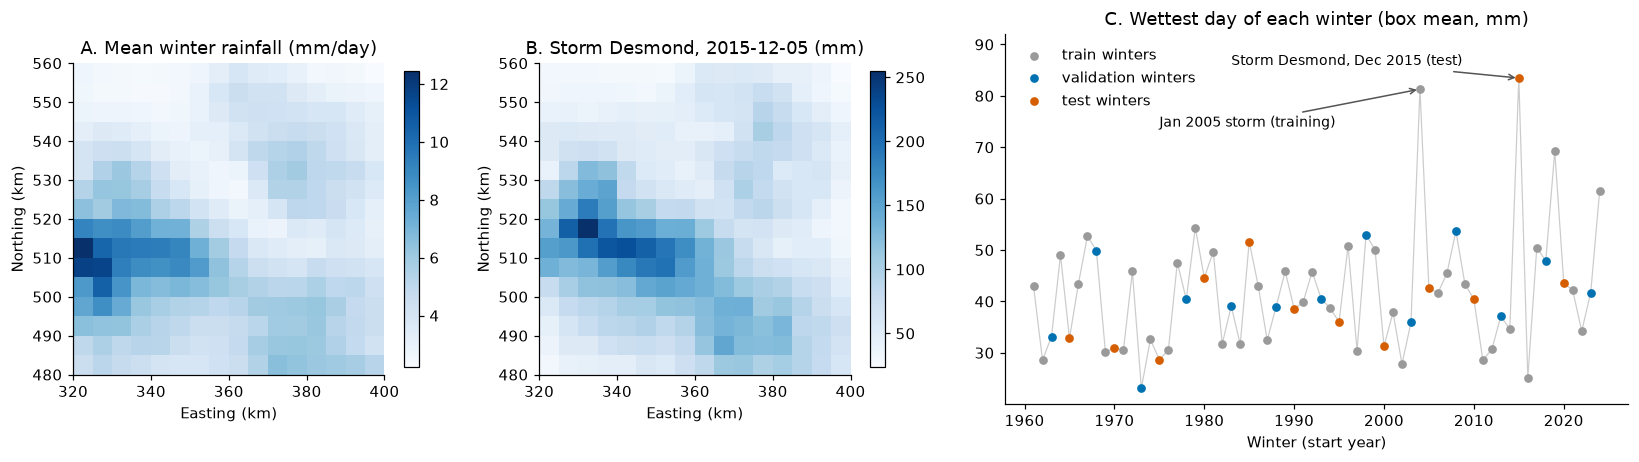

In [4]:
yr = x.mean((1, 2))
W = np.unique(winter)
wmax = np.array([yr[winter == w].max() for w in W])
wmean = np.array([yr[winter == w].mean() for w in W])
role = np.where(np.isin(W, sp.test_winters), "test", np.where(np.isin(W, sp.val_winters), "validation", "train"))
from scipy import stats
print("Trend in winter mean (Kendall):", stats.kendalltau(W, wmean))
print("Trend in winter maximum (Kendall):", stats.kendalltau(W, wmax))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1, 1, 1.6]})
lon_ext = [da.x.values[0] - 2500, da.x.values[-1] + 2500, da.y.values[0] - 2500, da.y.values[-1] + 2500]
ext = [v / 1000 for v in lon_ext]
im = axes[0].imshow(x.mean(0), origin="lower", extent=ext, cmap="Blues")
axes[0].set_title("A. Mean winter rainfall (mm/day)"); plt.colorbar(im, ax=axes[0], shrink=0.8)
im = axes[1].imshow(x[d], origin="lower", extent=ext, cmap="Blues")
axes[1].set_title(f"B. Storm Desmond, {DESMOND_DATE} (mm)"); plt.colorbar(im, ax=axes[1], shrink=0.8)
for a in axes[:2]:
    a.set_xlabel("Easting (km)"); a.set_ylabel("Northing (km)")
cols = {"train": "#9a9a9a", "validation": "#0072B2", "test": "#D55E00"}
for r in ["train", "validation", "test"]:
    m = role == r
    axes[2].scatter(W[m], wmax[m], s=22, color=cols[r], label=f"{r} winters", zorder=3)
axes[2].plot(W, wmax, color="#cccccc", lw=0.8, zorder=1)
axes[2].annotate("Storm Desmond, Dec 2015 (test)", (2015, wmax[W == 2015][0]), xytext=(1983, 86),
                 arrowprops=dict(arrowstyle="->", color="#555555"), fontsize=9)
axes[2].annotate("Jan 2005 storm (training)", (2004, wmax[W == 2004][0]), xytext=(1975, 74),
                 arrowprops=dict(arrowstyle="->", color="#555555"), fontsize=9)
axes[2].set_ylim(top=92)
axes[2].set_title("C. Wettest day of each winter (box mean, mm)")
axes[2].set_xlabel("Winter (start year)"); axes[2].legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig(FIGS / "data_overview.png", bbox_inches="tight"); plt.show()

**Trend.** Mean winter rainfall has increased over 1961–2025, while the trend in winter maxima is
smaller and not significant at the 5% level. The Kendall test treats winters as independent, so
its p-value is approximate. The generators in this pilot are
**stationary**, so they describe the 1961–2025 climate as a whole. Conditioning on climate, the
fourth research question of the E5 project, is outside the pilot's scope.

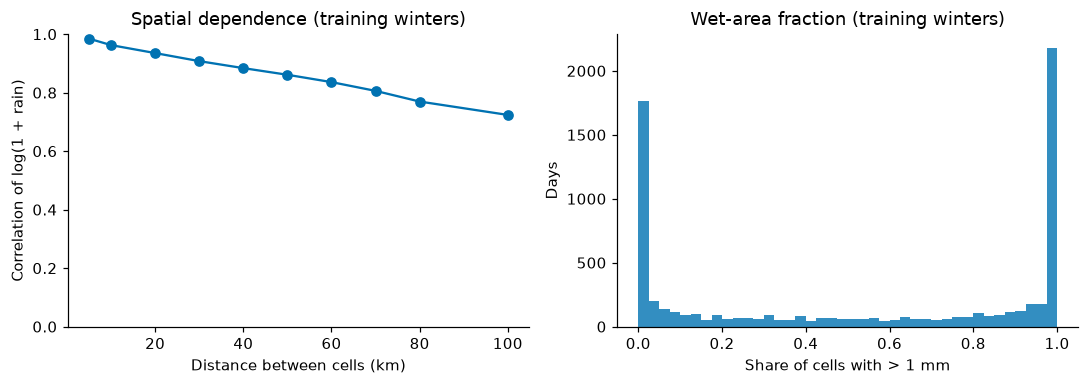

lag-1 autocorrelation of the box mean (within winters): 0.31


In [5]:
D = cell_distances_km()
C = np.corrcoef(np.log1p(X[sp.train]).T)
bins = DIST_BINS    # contiguous distance bands, labelled by their centre
corr_d = [C[(D > lo) & (D <= hi)].mean() for lo, hi in zip(DIST_EDGES[:-1], DIST_EDGES[1:])]
wet = (X[sp.train] > 1).mean(1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(bins, corr_d, "o-", color="#0072B2"); axes[0].set_ylim(0, 1)
axes[0].set_xlabel("Distance between cells (km)"); axes[0].set_ylabel("Correlation of log(1 + rain)")
axes[0].set_title("Spatial dependence (training winters)")
axes[1].hist(wet, bins=40, color="#0072B2", alpha=0.8)
axes[1].set_xlabel("Share of cells with > 1 mm"); axes[1].set_ylabel("Days")
axes[1].set_title("Wet-area fraction (training winters)")
plt.tight_layout(); plt.savefig(FIGS / "dependence_and_wet_area.png", bbox_inches="tight"); plt.show()
same = winter[:-1] == winter[1:]                       # consecutive days within one winter
print(f"lag-1 autocorrelation of the box mean (within winters): {np.corrcoef(yr[:-1][same], yr[1:][same])[0, 1]:.2f}")

**What this means for the models**

* Rainfall is strongly correlated across the box, still about 0.7 at 100 km, so a storm often
  covers much of the region. Area-averaged extremes therefore depend heavily on how well a
  generator captures **joint** extremes, not just single-cell ones.
* The wet-area fraction is spread across the whole range, from dry days to days when every cell
  is wet: the bulk of the distribution matters too.
* Consecutive days are correlated (about 0.3), so uncertainty is assessed by resampling **whole
  winters**, never single days.